In [1]:
import datajoint as dj

dj.config.load("dj_local_conf.json")

import numpy as np
from spyglass.position import PositionOutput
from spyglass.linearization.merge import LinearizedPositionOutput
import spyglass.common as sgc
import pandas as pd
import spyglass.linearization.v1 as sgpl

from mpfc_opto.behavior.forktrack_tables import (
    ForkTrackParams,
    ForkTrackSelection,
    ForkTrackEvents,
)
from mpfc_opto.glm.path_progression_tables import (
    PathProgressSelection,
    PathProgress,
)
from mpfc_opto.glm.glm_tables import GLMSelection, GLMStorage

[2026-11-01 22:48:33,905][INFO]: DataJoint is configured from /home/dmrodriguez/mPFC-opto/notebooks/dj_local_conf.json
[2026-11-01 22:48:35,499][INFO]: DataJoint 0.14.9 connected to denissemorales@lmf-db.cin.ucsf.edu:3306


In [2]:
from mpfc_opto.glm.basis import GLMBasisParams, GLMBasisSelection, GLMBasis

In [3]:
nwb_file_name = "Caius20260623_.nwb"
epoch = 6

In [4]:
GLM_storage = (GLMStorage() & {"epoch": epoch}).fetch_nwb()[0]
GLM_storage_df = GLM_storage["trial"]

/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/MarketTech LuxX+ Red/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/Optical fiber 1/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/Optical fiber 2/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning:

In [5]:
GLM_storage_df

,time,unit_0,unit_1,unit_2,unit_3,unit_4,unit_5,unit_6,unit_7,unit_8,...,path_type_none,path_type_right_to_handle,previous_arm,home_arm,previous_reward,current_reward,turn,previous_turn,nwb_file_name,epoch
id,,,,,,,,,,,,,,,,,,,,,
0,1.782244e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,True,False,none,none,NaN,NaN,none,none,Caius20260623_.nwb,6
1,1.782244e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,True,False,none,none,NaN,NaN,none,none,Caius20260623_.nwb,6
2,1.782244e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,True,False,none,none,NaN,NaN,none,none,Caius20260623_.nwb,6
3,1.782244e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,True,False,none,none,NaN,NaN,none,none,Caius20260623_.nwb,6
4,1.782244e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,True,False,none,none,NaN,NaN,none,none,Caius20260623_.nwb,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
24706,1.782245e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,False,False,Right_poke,handle,1.0,1.0,left,right,Caius20260623_.nwb,6
24707,1.782245e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,False,False,Right_poke,handle,1.0,1.0,left,right,Caius20260623_.nwb,6
24708,1.782245e+09,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,False,False,Right_poke,handle,1.0,1.0,left,right,Caius20260623_.nwb,6


In [6]:
GLMBasisParams()

basis_param_id unique identifier for this basis parameter set,basis_param_name name of the basis parameter set,basis_param_description description of the basis parameter set,"var_names list of variable names (design-matrix groups) to include,","basis_params kwargs forwarded to build_bases() (n_basis_funcs_*, ranges, grid sizes, ...)",occupancy_sd_thresh bases with std <= this (no occupancy) are dropped
2,default_basis_with_trajectory_progress,"Default basis set plus trajectory_progress (the 'ppt' variable proper) and its reward/turn/arm/path/segment interactions, alongside everything already in linear position, 2D position, speed, and orientation.",=BLOB=,=BLOB=,0.01


In [7]:
key = (GLMStorage() & {"nwb_file_name": "Caius20260623_.nwb"}).fetch("KEY")[0]

key.update({"basis_param_id": 1, "basis_param_name": "default_basis"})

key

{'nwb_file_name': 'Caius20260623_.nwb',
 'merge_id': UUID('b01c18a5-a23f-9ca1-57e4-f2ad0774c682'),
 'forktrack_params_name': 'default',
 'pos_merge_id': UUID('5f1240f9-46c7-d61e-60e1-acc64e8c5e6b'),
 'track_graph_name': 'dmr fork caius',
 'unit_filter_params_name': 'exclude_all_other',
 'sorted_spikes_group_name': 'mPFC_opto',
 'interval_list_name': '06_r3',
 'basis_param_id': 1,
 'basis_param_name': 'default_basis'}

In [9]:
# GLMBasisSelection().insert1(key)

In [ ]:
# GLMBasis.Kernel().alter()

In [11]:
GLMBasis()

nwb_file_name name of the NWB file,merge_id,forktrack_params_name,pos_merge_id,track_graph_name,unit_filter_params_name,sorted_spikes_group_name,interval_list_name descriptive name of this interval list,basis_param_id unique identifier for this basis parameter set,basis_param_name name of the basis parameter set,n_samples number of timebins (rows of X),n_features number of design-matrix columns,n_groups number of variable groups (for group_lasso),"design_matrix_object_id object id for design matrix X, shape (n_samples, n_features)",feature_names_object_id object id for per-column feature names,group_ind_object_id object id for per-column group index,feature_group_mask_object_id object id for (n_groups x n_features) group membership mask,unit_names_object_id object id for unit_* column names/order used for Y,analysis_file_name name of the file
Caius20260623_.nwb,b01c18a5-a23f-9ca1-57e4-f2ad0774c682,default,5f1240f9-46c7-d61e-60e1-acc64e8c5e6b,dmr fork caius,exclude_all_other,mPFC_opto,06_r3,2,default_basis_with_trajectory_progress,24711,1227,26,8cd314e9-3c4c-4a6f-bae5-cd9329eeb51e,c8b0d056-8265-462b-9fb1-839965241056,3fac3f72-1baf-4113-9d48-ccfb64479d46,5fd3b68a-4cd0-44d5-bf41-9250a4446dd4,e9fdab73-9038-4f22-a056-df5ac29eeb5d,Caius20260623_00WM7YSIUS.nwb


In [12]:
GLMBasis()

nwb_file_name name of the NWB file,merge_id,forktrack_params_name,pos_merge_id,track_graph_name,unit_filter_params_name,sorted_spikes_group_name,interval_list_name descriptive name of this interval list,basis_param_id unique identifier for this basis parameter set,basis_param_name name of the basis parameter set,n_samples number of timebins (rows of X),n_features number of design-matrix columns,n_groups number of variable groups (for group_lasso),"design_matrix_object_id object id for design matrix X, shape (n_samples, n_features)",feature_names_object_id object id for per-column feature names,group_ind_object_id object id for per-column group index,feature_group_mask_object_id object id for (n_groups x n_features) group membership mask,unit_names_object_id object id for unit_* column names/order used for Y,analysis_file_name name of the file
Caius20260623_.nwb,b01c18a5-a23f-9ca1-57e4-f2ad0774c682,default,5f1240f9-46c7-d61e-60e1-acc64e8c5e6b,dmr fork caius,exclude_all_other,mPFC_opto,06_r3,2,default_basis_with_trajectory_progress,24711,1227,26,8cd314e9-3c4c-4a6f-bae5-cd9329eeb51e,c8b0d056-8265-462b-9fb1-839965241056,3fac3f72-1baf-4113-9d48-ccfb64479d46,5fd3b68a-4cd0-44d5-bf41-9250a4446dd4,e9fdab73-9038-4f22-a056-df5ac29eeb5d,Caius20260623_00WM7YSIUS.nwb


In [13]:
GLMBasis().populate()

{'success_count': 0, 'error_list': []}

In [14]:
from mpfc_opto.glm.glm_fit_tables import GLMFit

## GLM fit diagnostics (Caius20260623_, epoch 6)

In [15]:
import sys, os
import numpy as np
import matplotlib.pyplot as plt

# glm_plots.py lives next to this notebook
sys.path.insert(0, os.getcwd())
import glm_plots as gp
from mpfc_opto.glm.glm_fit_tables import GLMFit, GLMFitParams

basis_key = (GLMBasis() & {"nwb_file_name": nwb_file_name, "epoch": epoch}).fetch("KEY")[0]
fit_keys = (GLMFit() & basis_key).fetch("KEY")
print(f"{len(fit_keys)} GLMFit entries for this basis")
fit_keys

1 GLMFit entries for this basis


[{'nwb_file_name': 'Caius20260623_.nwb',
  'merge_id': UUID('b01c18a5-a23f-9ca1-57e4-f2ad0774c682'),
  'forktrack_params_name': 'default',
  'pos_merge_id': UUID('5f1240f9-46c7-d61e-60e1-acc64e8c5e6b'),
  'track_graph_name': 'dmr fork caius',
  'unit_filter_params_name': 'exclude_all_other',
  'sorted_spikes_group_name': 'mPFC_opto',
  'interval_list_name': '06_r3',
  'basis_param_id': 2,
  'basis_param_name': 'default_basis_with_trajectory_progress',
  'fit_param_id': 1,
  'fit_param_name': 'default_ridge'}]

In [16]:
fit_key = fit_keys[0]

fit_results_df = GLMFit().fetch_fit_results(fit_key)
w, w0, feature_names = GLMFit().fetch_coefficients(fit_key)
kernels = GLMBasis().fetch_kernels(fit_key)

# GLMBasis entries built before kernel_trajectory_progress was stored: rebuild it
# from the GLMStorage dataframe with the entry's own basis parameters
if "kernel_trajectory_progress" not in kernels:
    from mpfc_opto.glm.basis_utils import trajectory_progress_kernel
    from mpfc_opto.glm.basis import GLMBasisParams

    n_tp = (GLMBasisParams() & fit_key).fetch1("basis_params")["n_basis_funcs_trajectory_progress"]
    kernels["kernel_trajectory_progress"] = trajectory_progress_kernel(GLM_storage_df, n_tp)

print("coef:", w.shape, " intercept:", w0.shape, " kernels:", list(kernels))
fit_results_df.head()

/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/MarketTech LuxX+ Red/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/Optical fiber 1/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning: Path to Group altered/broken at /general/devices/Optical fiber 2/model
  warnings.warn('Path to Group altered/broken at ' + os.path.join(h5obj.name, k), BrokenLinkWarning)
/home/dmrodriguez/python_venvs/nemos/lib/python3.10/site-packages/hdmf/backends/hdf5/h5tools.py:620: BrokenLinkWarning:

coef: (1227, 63)  intercept: (63,)  kernels: ['kernel_linpos', 'kernel_pos', 'kernel_speed', 'kernel_orientation', 'kernel_trajectory_progress']


,unit_name,frac_dev_expl_train,frac_dev_expl_cv,selected_lambda,selected_lambda_ind
id,,,,,
0,unit_0,0.251871,0.214228,0.001172,8
1,unit_1,0.089305,0.078148,0.018874,3
2,unit_2,0.111821,0.093117,0.006210,5
3,unit_3,0.350016,0.338923,0.010826,4
4,unit_4,0.122970,0.105841,0.010826,4


### Per-unit fit quality

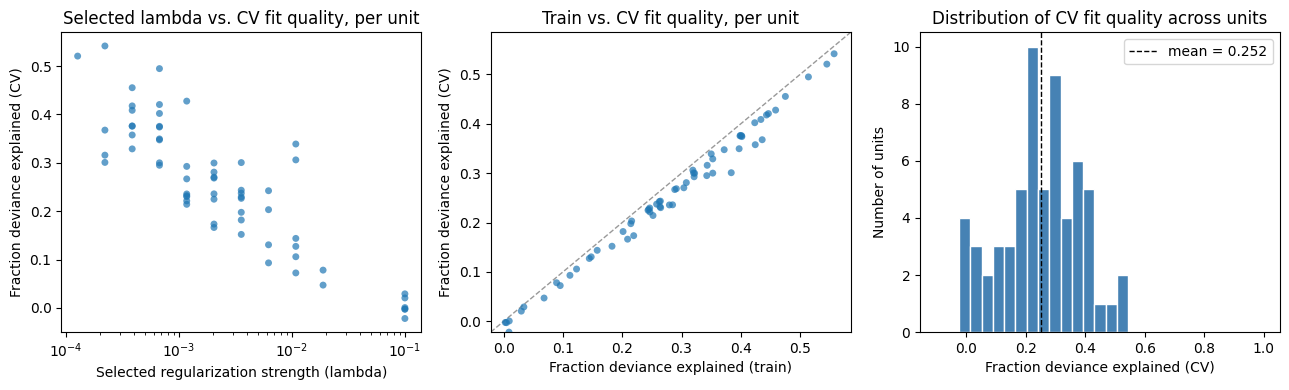

In [17]:
fig, axes = gp.summary_panel(fit_results_df)
plt.show()

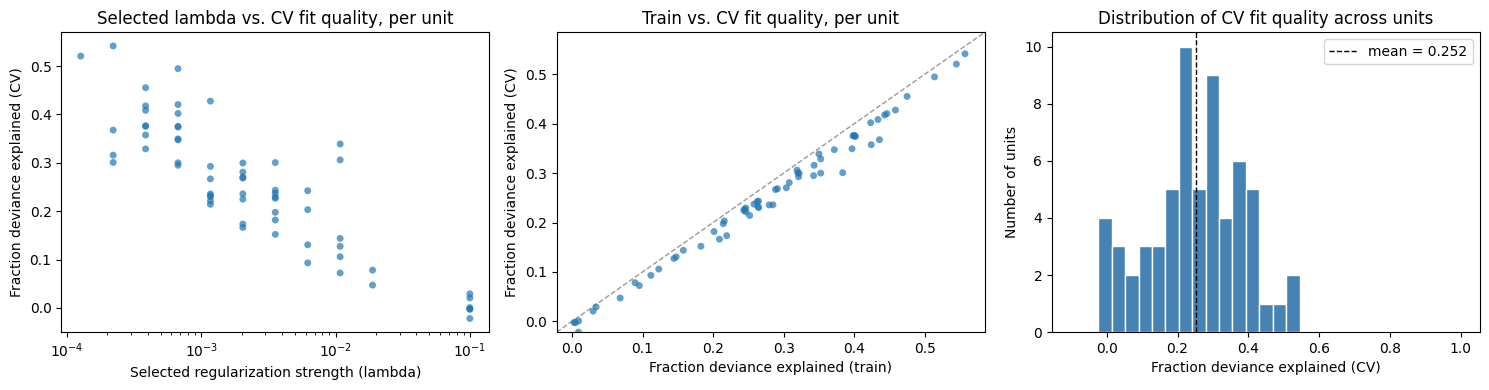

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
gp.plot_regularization_scatter(fit_results_df, ax=axes[0])
gp.plot_train_vs_cv(fit_results_df, ax=axes[1])
gp.plot_frac_dev_expl_hist(fit_results_df, ax=axes[2])
plt.tight_layout()
plt.show()

### Tuning curves
`plot_regularization_path` is not called here: it needs a live, already-fit `PopulationGLM_CV` object, and `GLMFit` only stores the selected lambda per unit (see its docstring).

In [19]:
# Best-fitting unit by CV deviance explained, used for the single-unit plots below
unit_idx = int(np.nanargmax(fit_results_df["frac_dev_expl_cv"].values))
unit_name = fit_results_df["unit_name"].iloc[unit_idx]
print(unit_idx, unit_name)

# which base variables are in this basis (kernel stored AND feature columns present)
usable_1d, has_place_field, skipped = gp._usable_covariates(
    kernels, feature_names, ("linear_position", "trajectory_progress", "speed", "orientation")
)
print("1D:", usable_1d, "| place field:", has_place_field, "| skipped (occupancy-thresholded):", skipped)

44 unit_44
1D: ['linear_position', 'trajectory_progress', 'speed', 'orientation'] | place field: False | skipped (occupancy-thresholded): ['pos_2d']


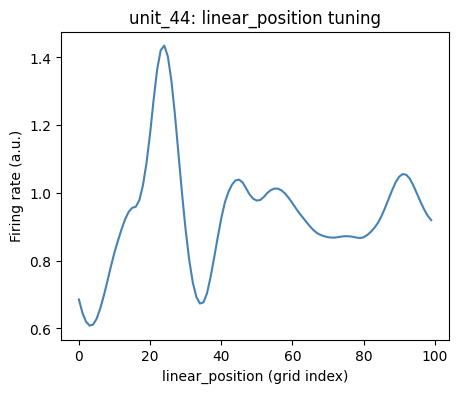

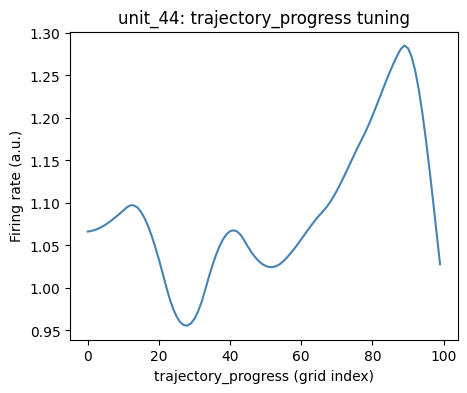

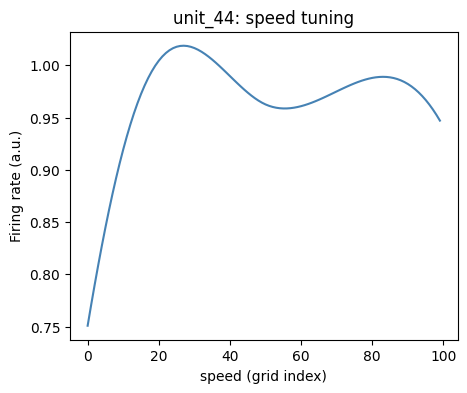

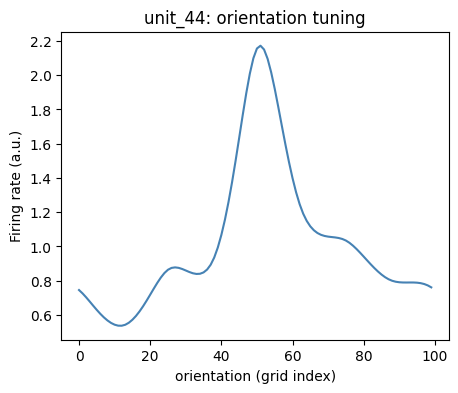

In [20]:
for var in usable_1d:
    gp.plot_tuning_curve_1d(
        kernels, w, feature_names, var, unit_idx=unit_idx, unit_name=unit_name, intercept=w0
    )
    plt.show()

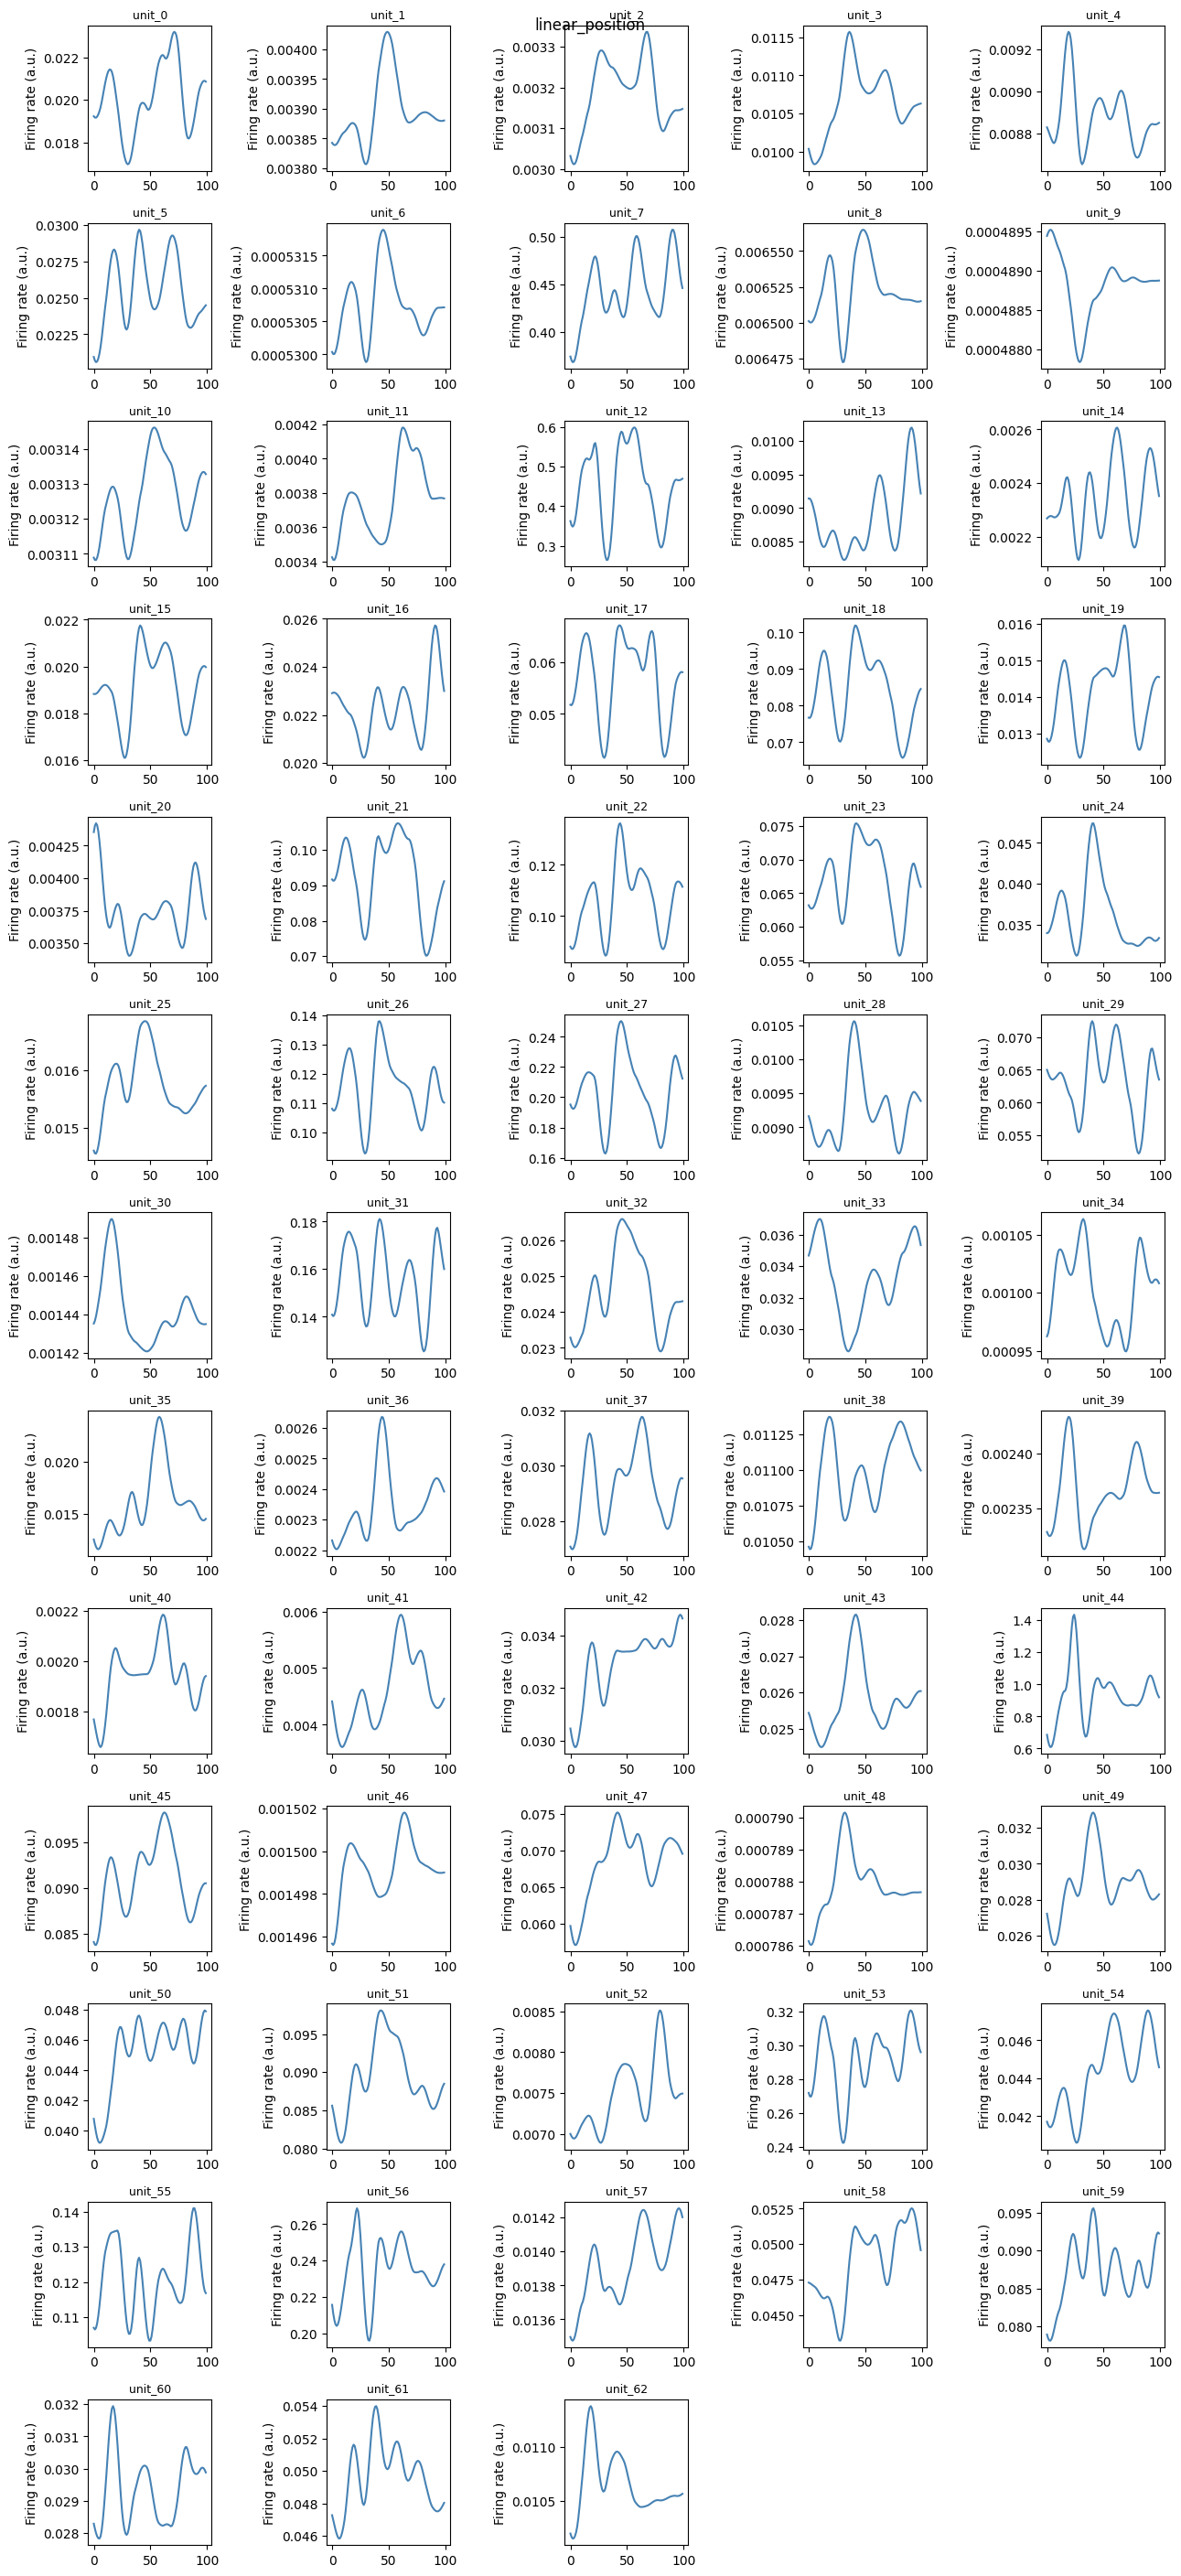

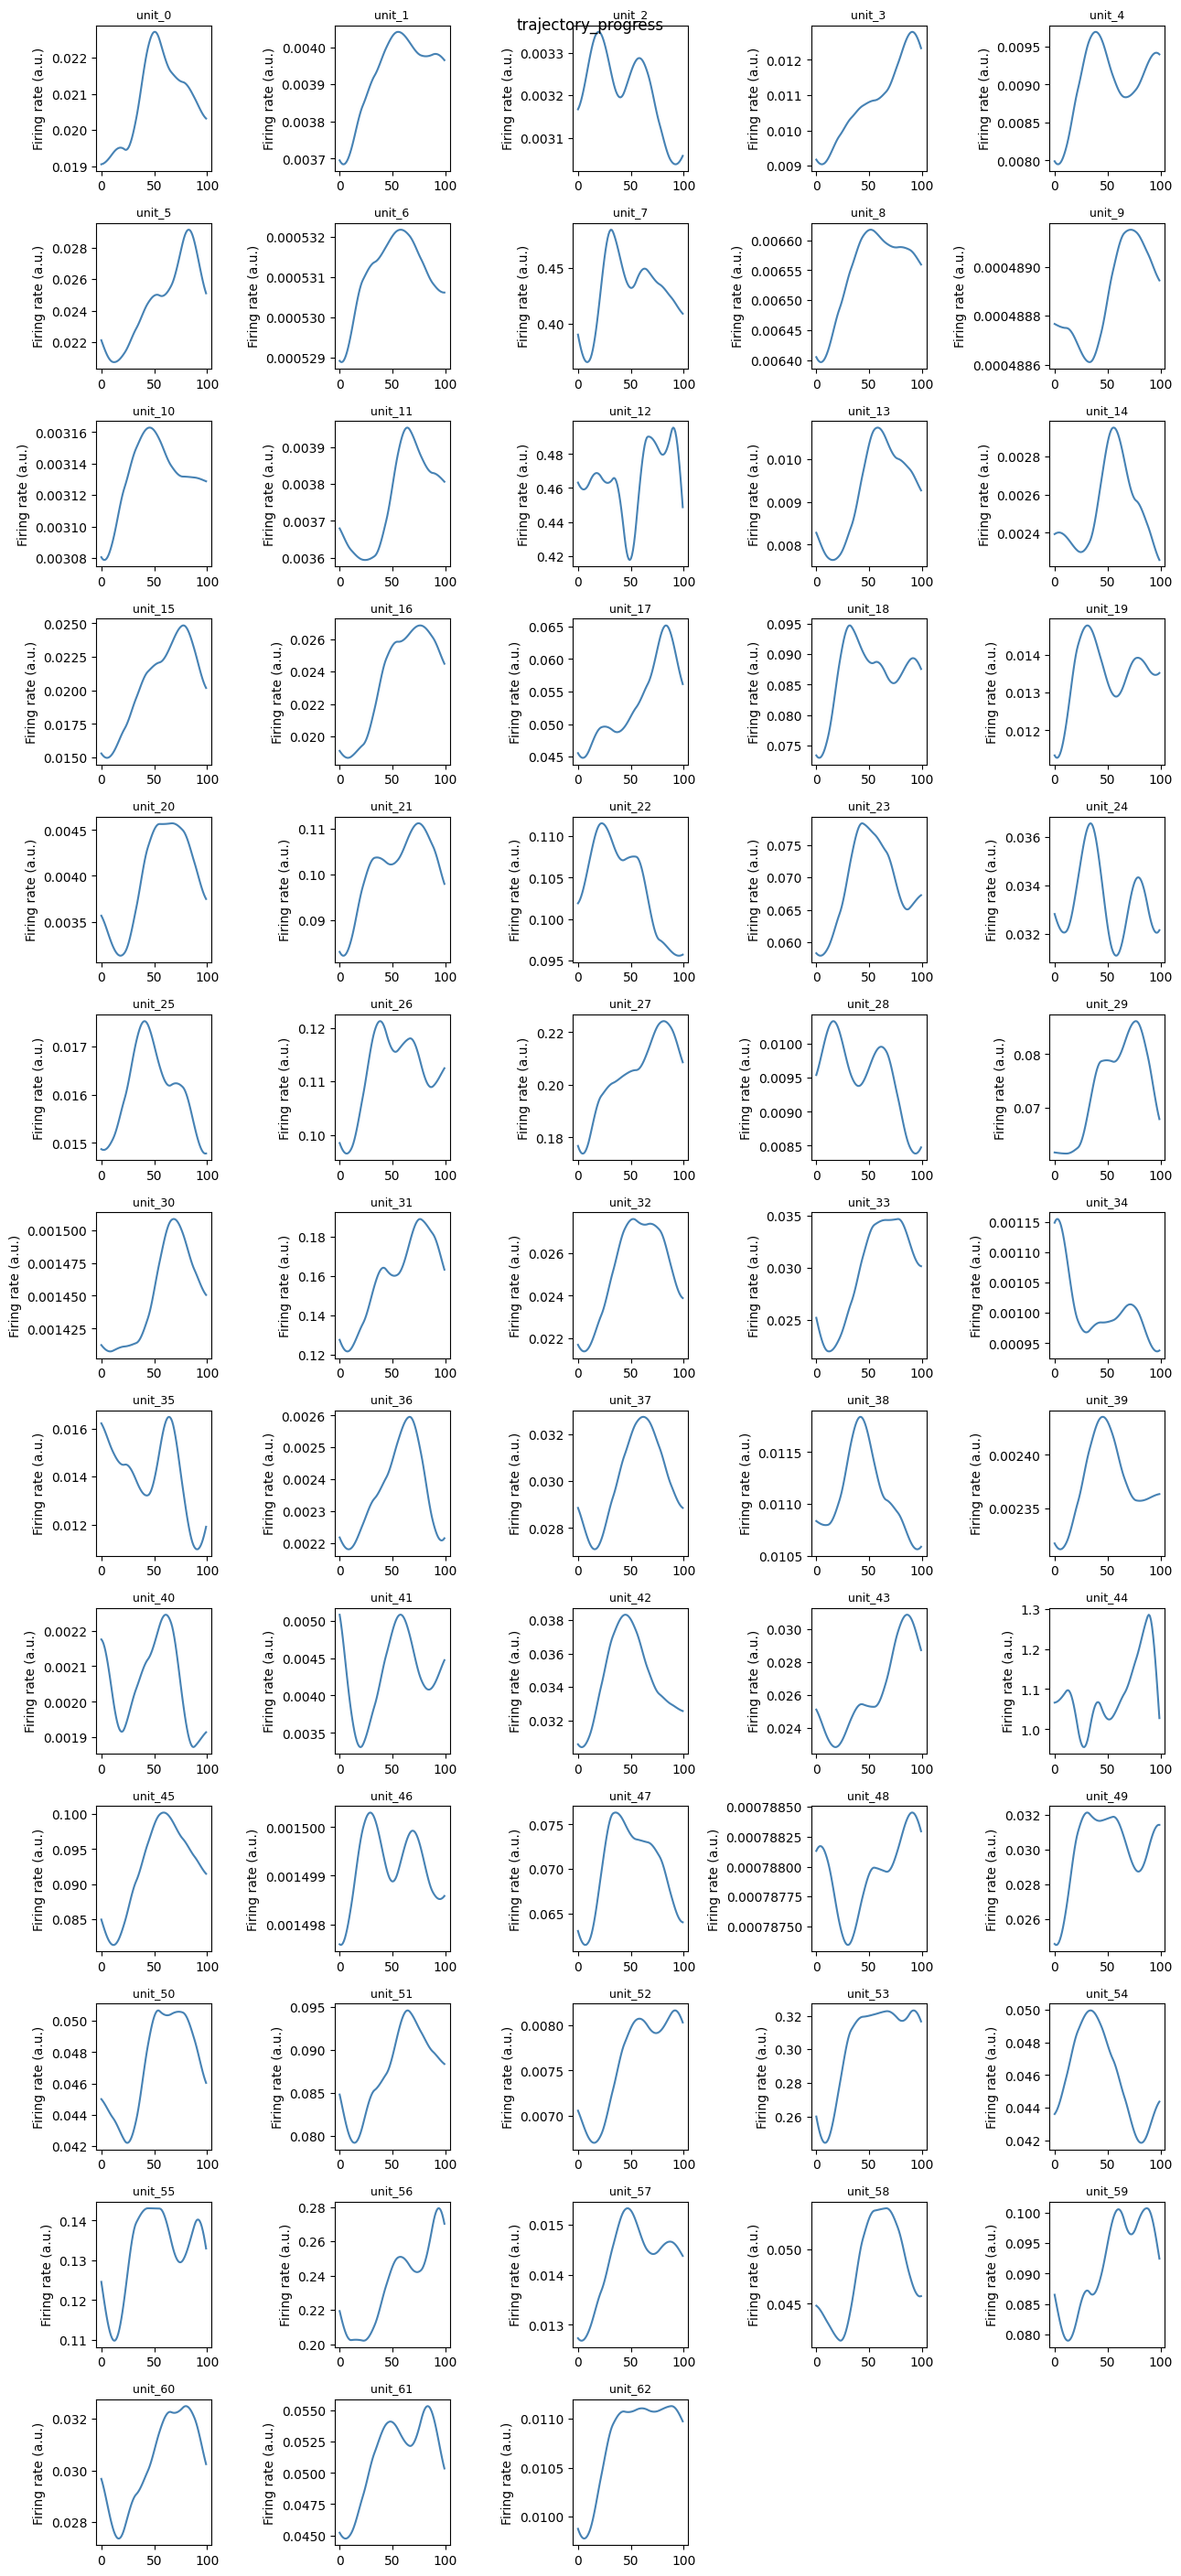

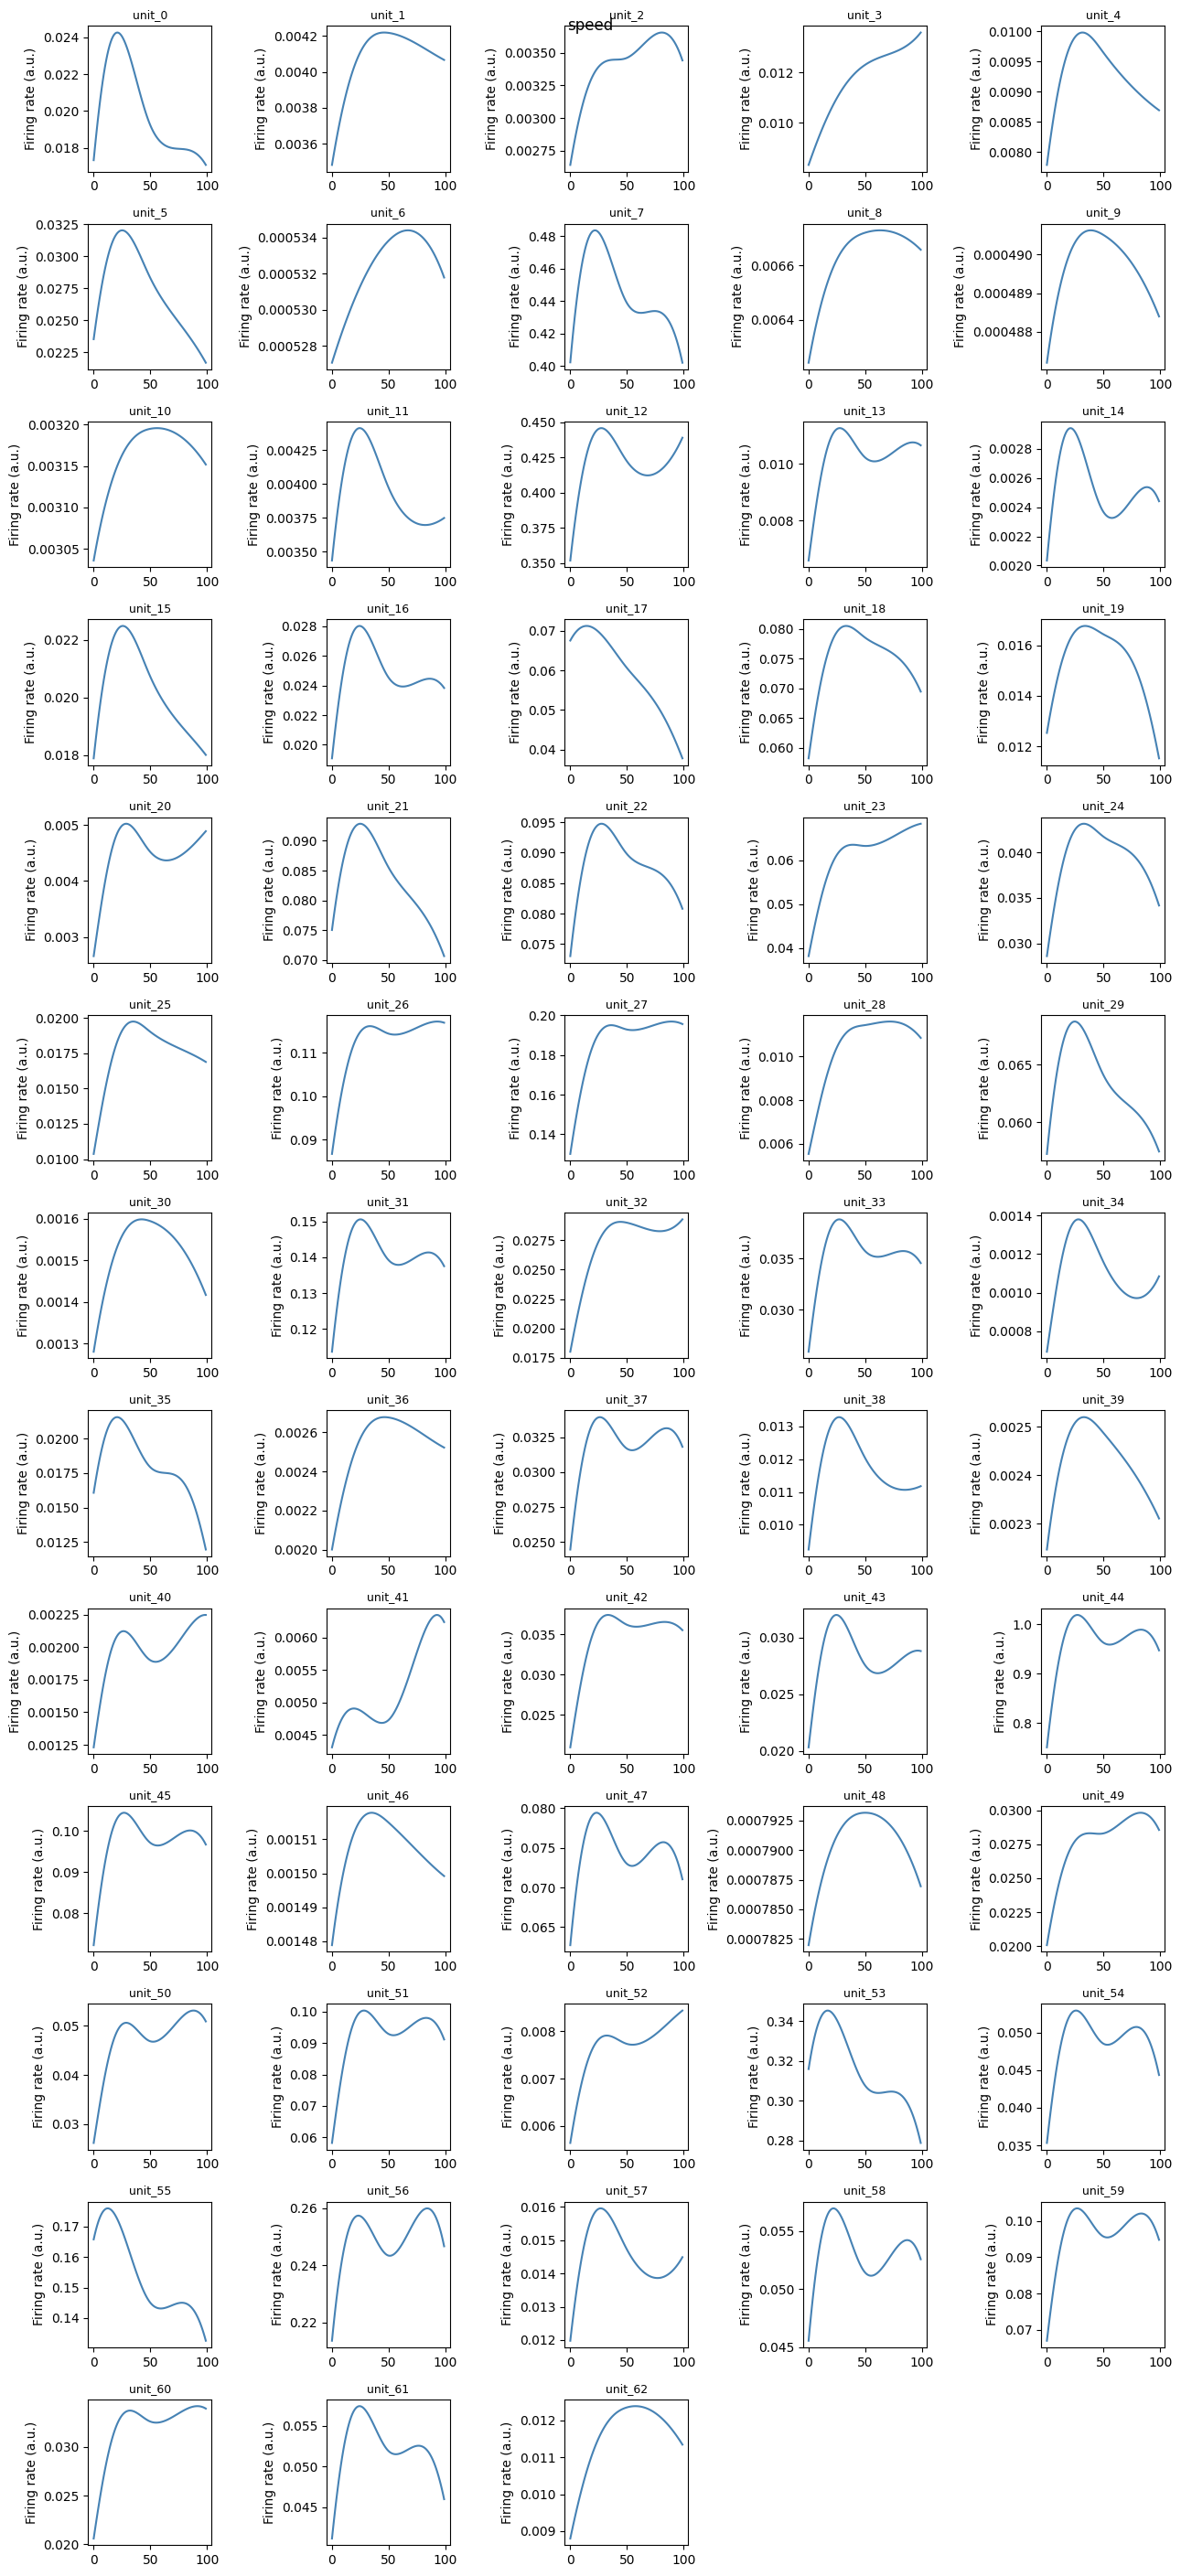

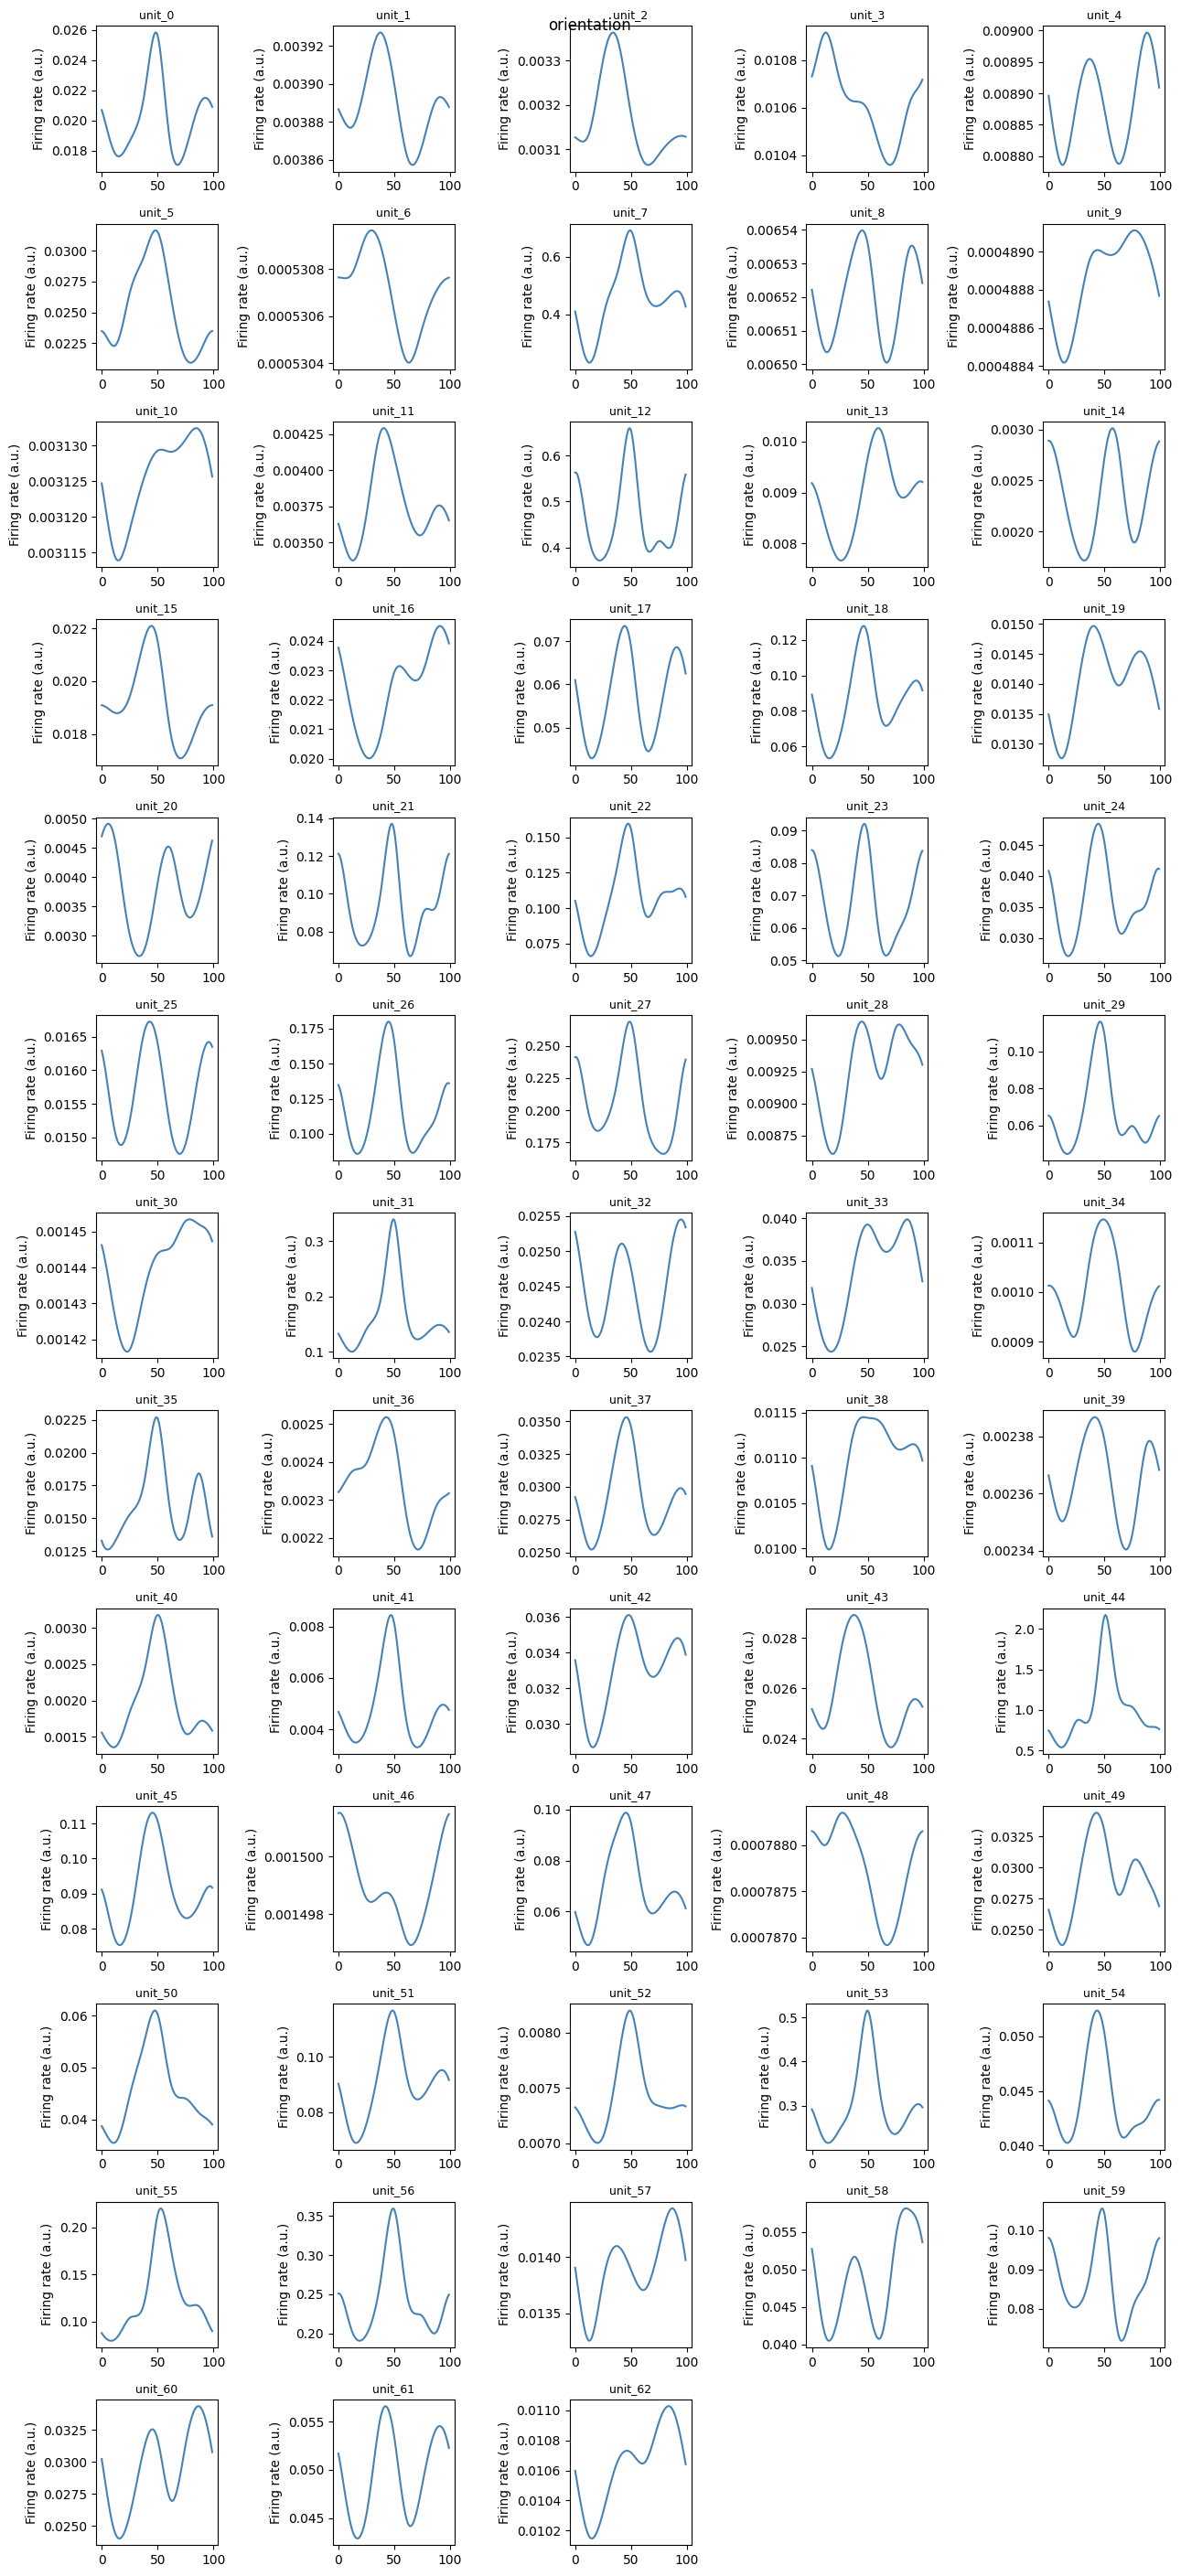

In [21]:
for var in usable_1d:
    gp.plot_tuning_curves_grid(
        kernels, w, feature_names, var,
        unit_names=fit_results_df["unit_name"].tolist(), intercept=w0,
    )
    plt.suptitle(var)
    plt.show()

In [22]:
if has_place_field:
    gp.plot_place_field(
        kernels, w, feature_names, unit_idx=unit_idx, unit_name=unit_name, intercept=w0
    )
    plt.show()
else:
    print("No usable pos_2d place field in this basis")

No usable pos_2d place field in this basis


plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


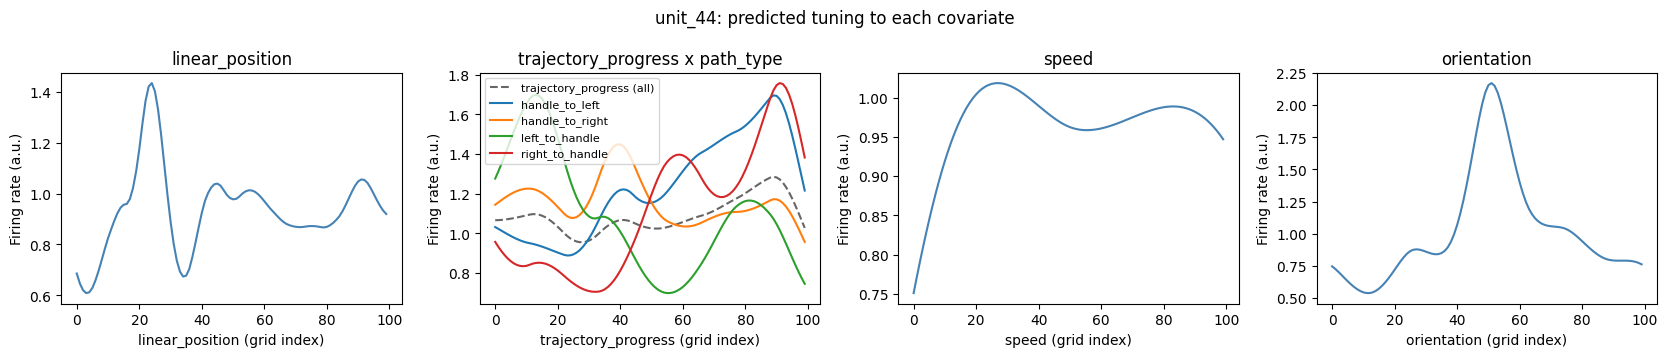

In [23]:
gp.plot_unit_tuning_summary(
    kernels, w, feature_names, unit_idx=unit_idx, unit_name=unit_name, intercept=w0
)
plt.show()

In [24]:
# One page per unit, all units
gp.save_tuning_summaries_pdf(
    kernels, w, feature_names,
    unit_names=fit_results_df["unit_name"].tolist(), intercept=w0,
    path="tuning_summaries.pdf",
)

plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)
plot_unit_tuning_summary: skipping ['pos_2d'] (not in this bas

'tuning_summaries.pdf'

### Categorical interactions and raw exp(beta)
Interactions built on linear position (`linpos_turn`, `linpos_reward`, ...) reuse the `linear_position` kernel. Only the ones present in this basis are plotted.

present in this fit: [('linear_position', 'linpos_turn'), ('linear_position', 'linpos_prev_turn'), ('linear_position', 'linpos_upcoming_turn'), ('linear_position', 'linpos_prev_arm'), ('linear_position', 'linpos_home_arm'), ('linear_position', 'linpos_segment'), ('trajectory_progress', 'trajectory_progress_turn'), ('trajectory_progress', 'trajectory_progress_prev_turn'), ('trajectory_progress', 'trajectory_progress_upcoming_turn'), ('trajectory_progress', 'trajectory_progress_prev_arm'), ('trajectory_progress', 'trajectory_progress_home_arm'), ('trajectory_progress', 'trajectory_progress_segment'), ('trajectory_progress', 'trajectory_progress_path_type')]
plot_categorical_interaction: skipping categories ['left', 'none'] for 'linpos_turn' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


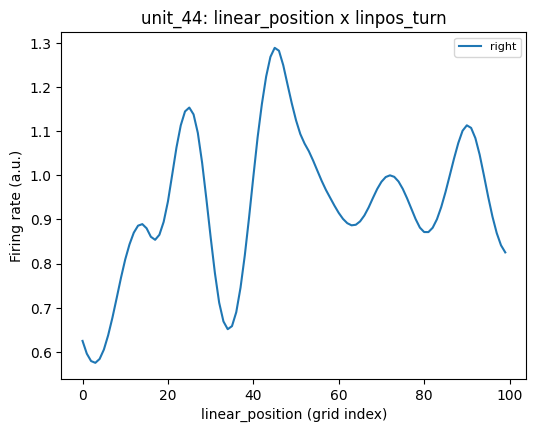

plot_categorical_interaction: skipping categories ['left', 'none'] for 'linpos_prev_turn' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


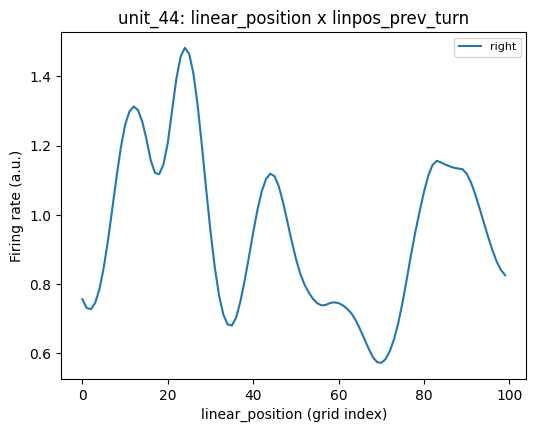

plot_categorical_interaction: skipping categories ['left', 'right'] for 'linpos_upcoming_turn' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


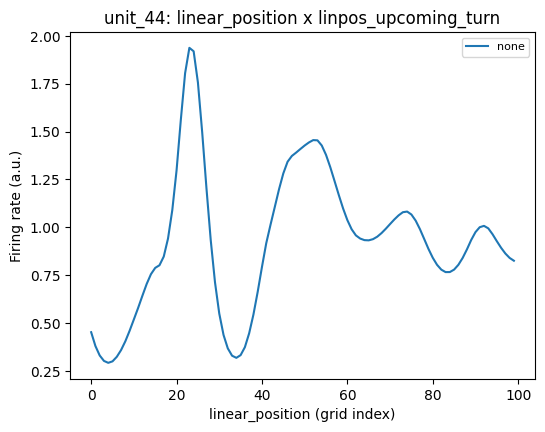

plot_categorical_interaction: skipping categories ['Left_poke', 'None', 'Right_poke', 'none'] for 'linpos_prev_arm' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


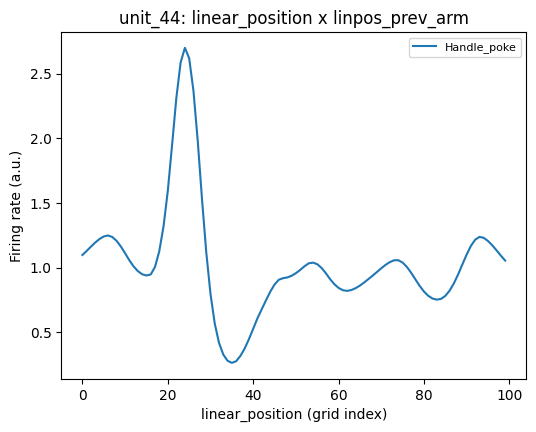

plot_categorical_interaction: skipping categories ['none'] for 'linpos_home_arm' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


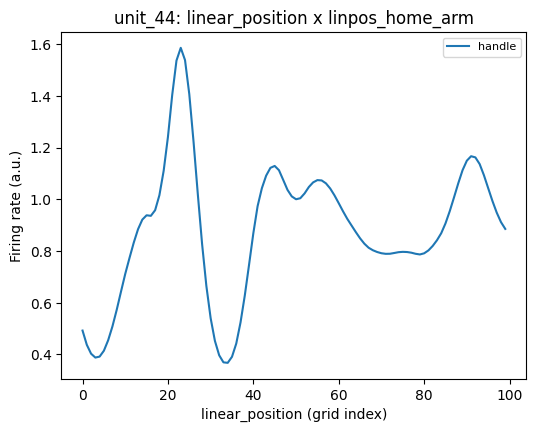

plot_categorical_interaction: skipping categories ['0', '1', '2', '3', '4', '5'] for 'linpos_segment' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


/home/dmrodriguez/mPFC-opto/notebooks/glm_plots.py:707: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax.legend(fontsize=8)


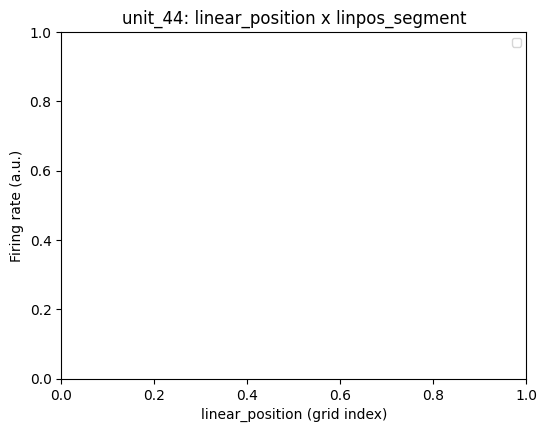

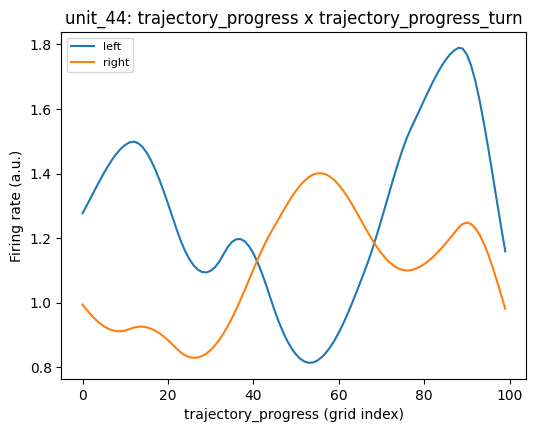

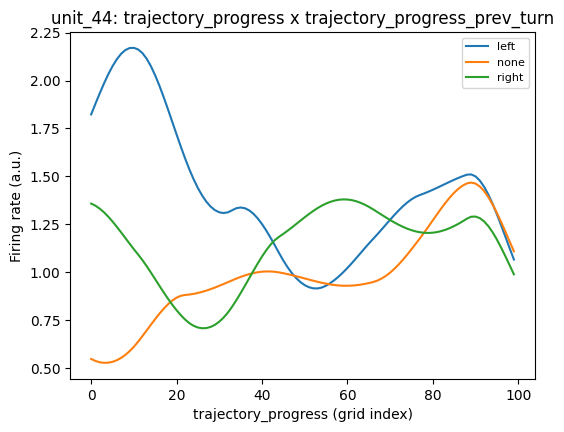

plot_categorical_interaction: skipping categories ['left'] for 'trajectory_progress_upcoming_turn' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


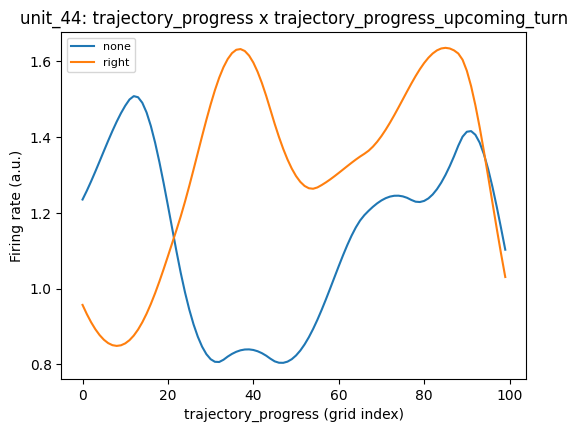

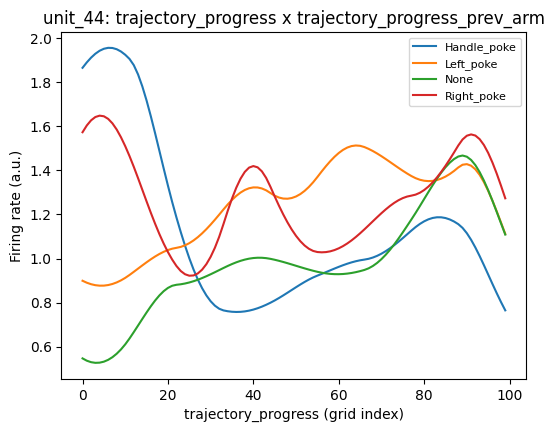

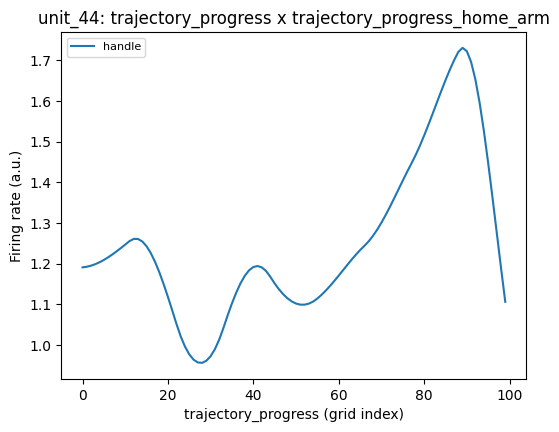

plot_categorical_interaction: skipping categories ['1', '3', '5'] for 'trajectory_progress_segment' (missing from this basis, or occupancy-thresholded -- see reconstruct_tuning_curve docstring)


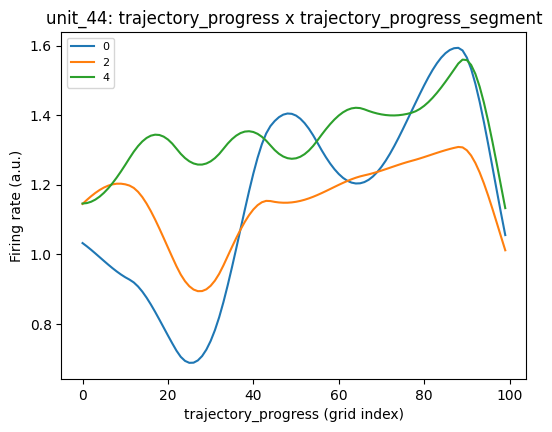

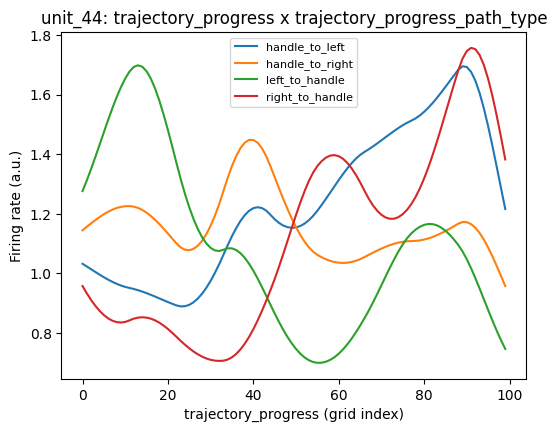

In [25]:
# (base variable, interaction prefix): interactions reuse their base variable's kernel
bases = {
    "linear_position": [
        "linpos_reward", "linpos_prev_reward", "linpos_turn", "linpos_prev_turn",
        "linpos_upcoming_turn", "linpos_prev_arm", "linpos_home_arm",
        "linpos_segment", "linpos_path_type",
    ],
    "trajectory_progress": [
        "trajectory_progress_reward", "trajectory_progress_prev_reward",
        "trajectory_progress_turn", "trajectory_progress_prev_turn",
        "trajectory_progress_upcoming_turn", "trajectory_progress_prev_arm",
        "trajectory_progress_home_arm", "trajectory_progress_segment",
        "trajectory_progress_path_type",
    ],
}
present = [
    (base, cat)
    for base, cats in bases.items() if base in usable_1d
    for cat in cats if gp._category_labels_for_interaction(feature_names, cat)
]
print("present in this fit:", present)

for base, cat in present:
    gp.plot_categorical_interaction(
        kernels, w, feature_names, base, cat,
        unit_idx=unit_idx, unit_name=unit_name, intercept=w0,
    )
    plt.show()

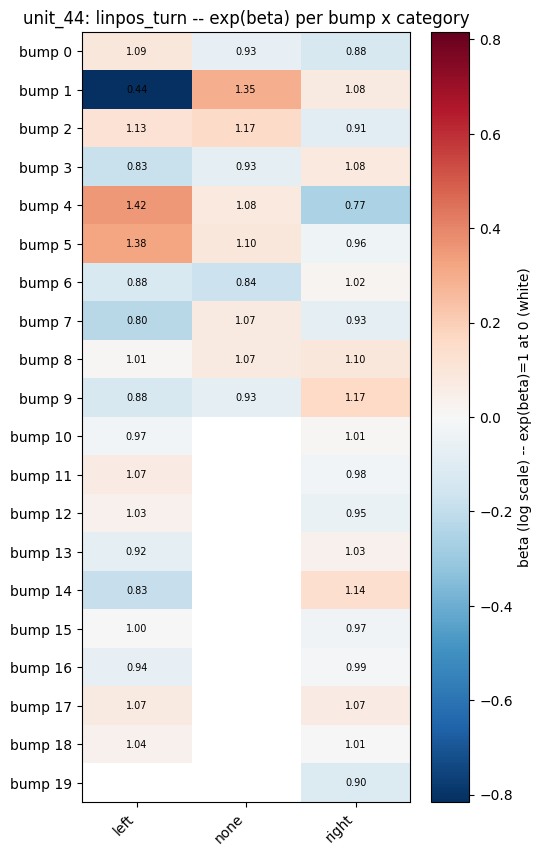

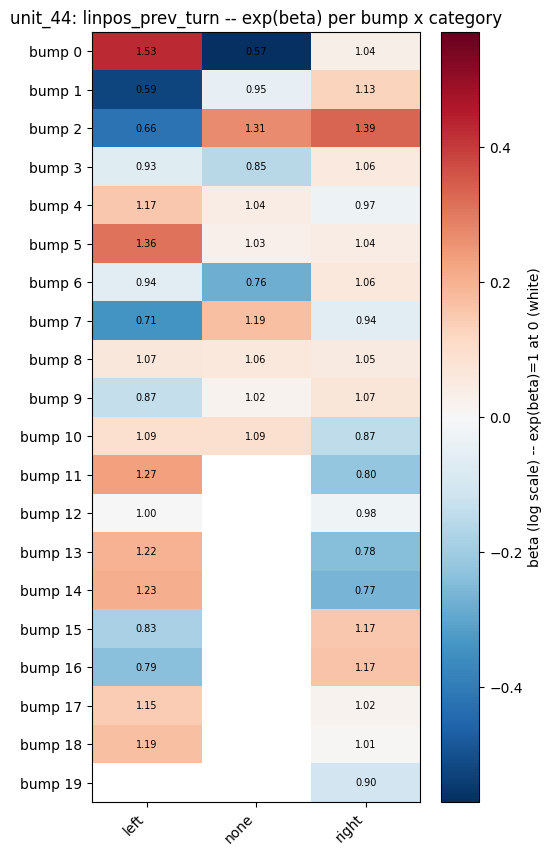

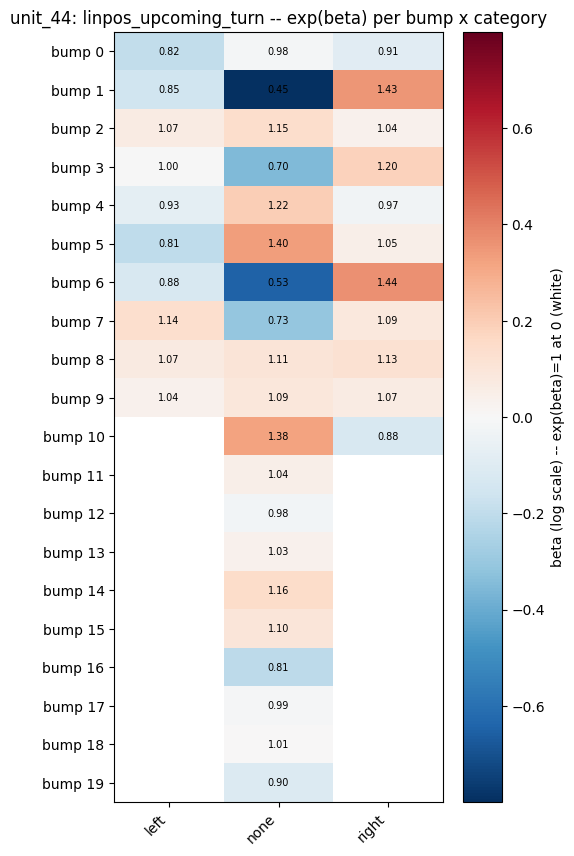

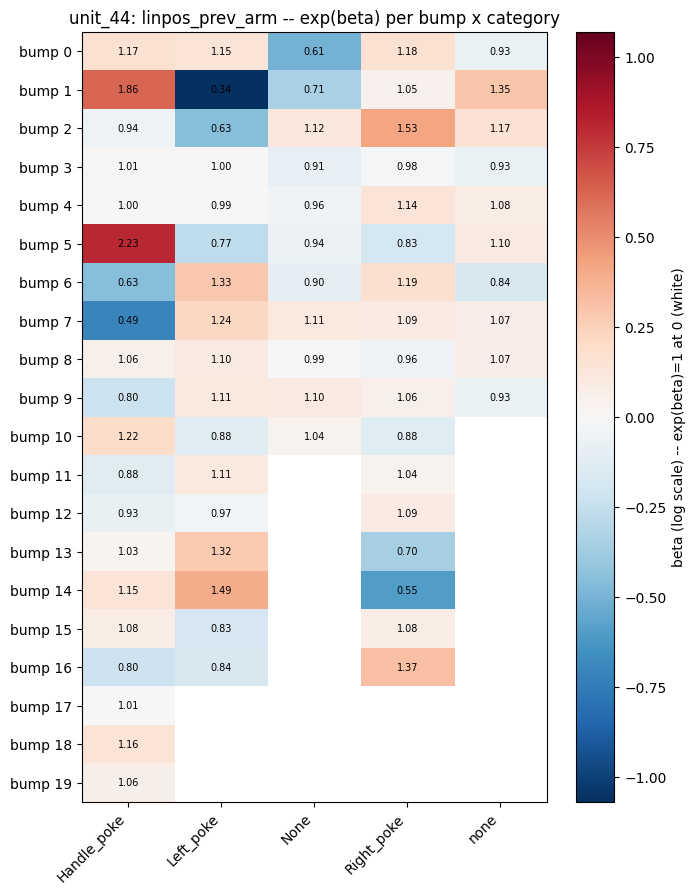

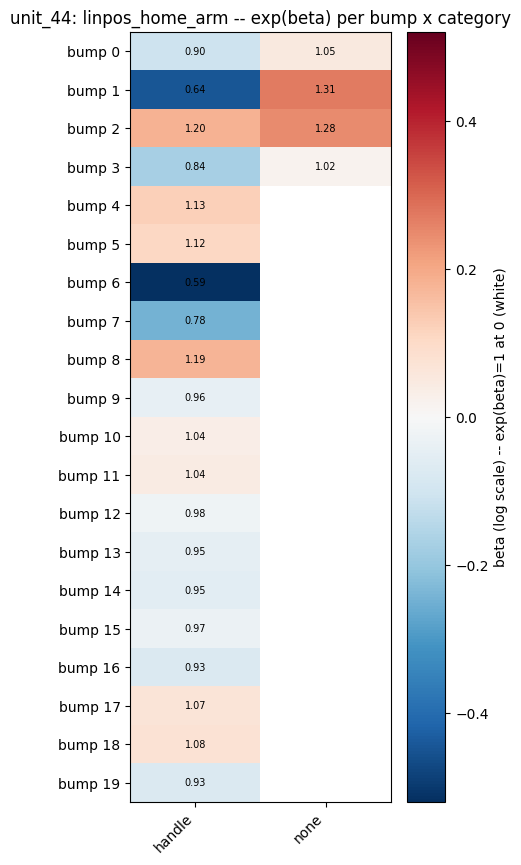

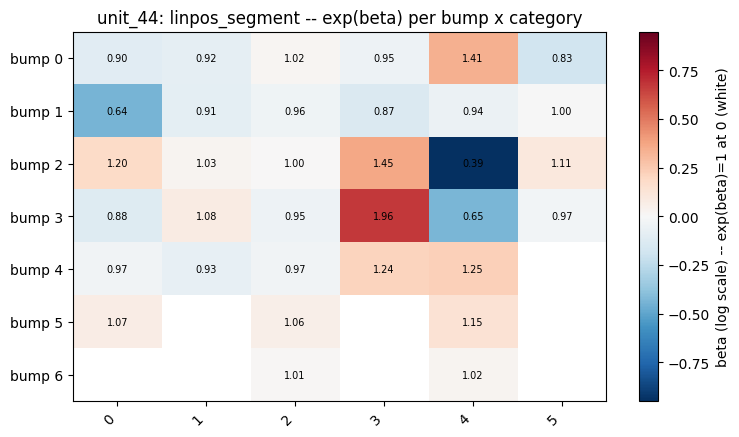

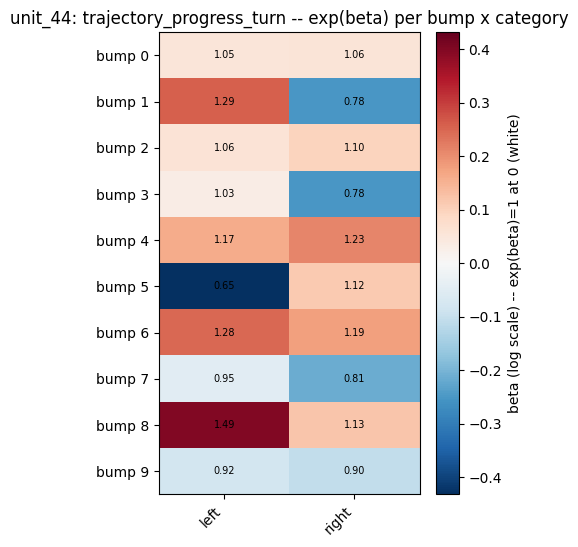

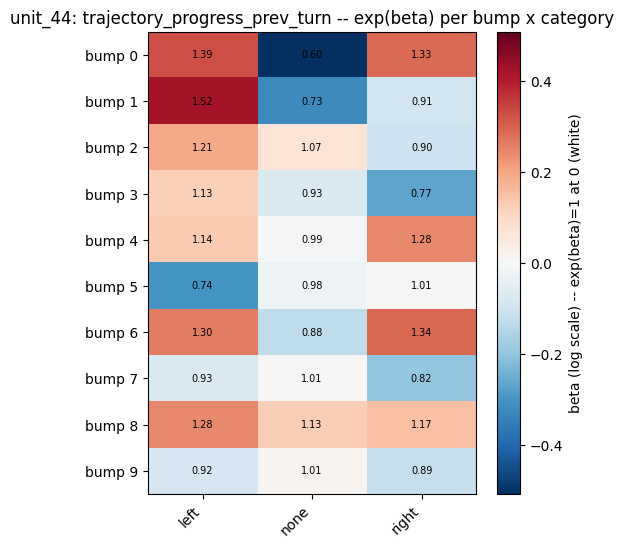

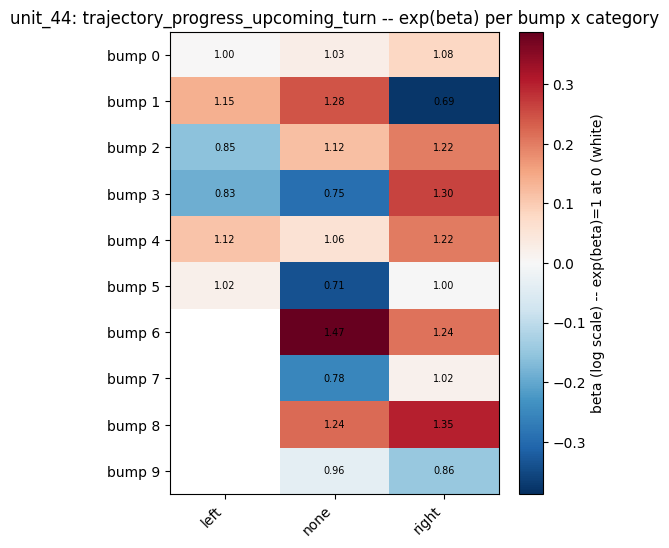

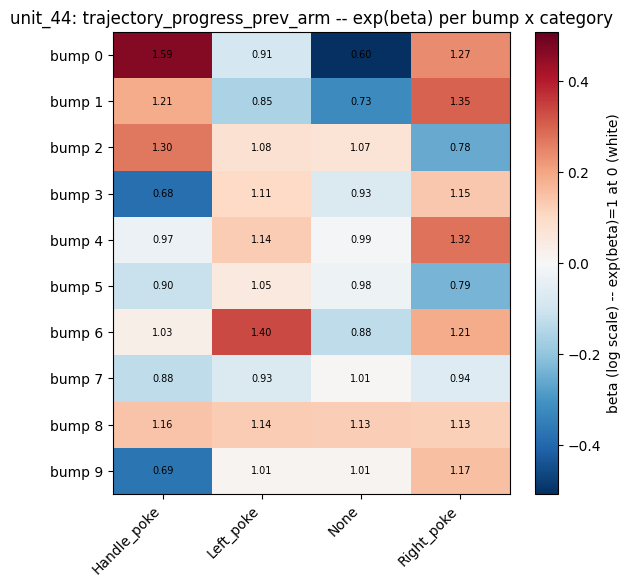

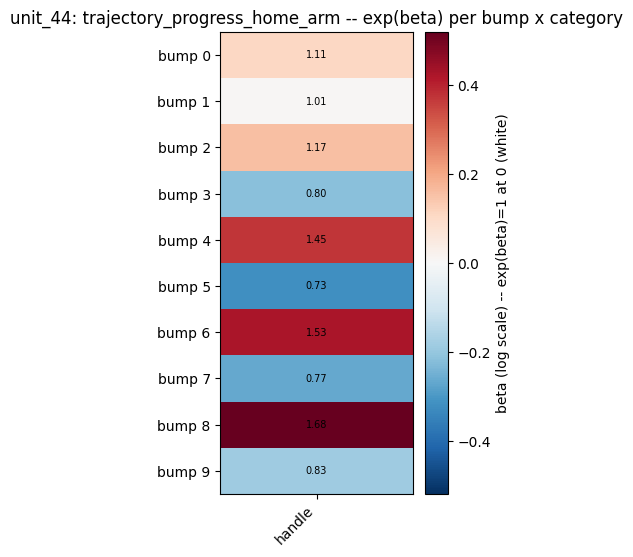

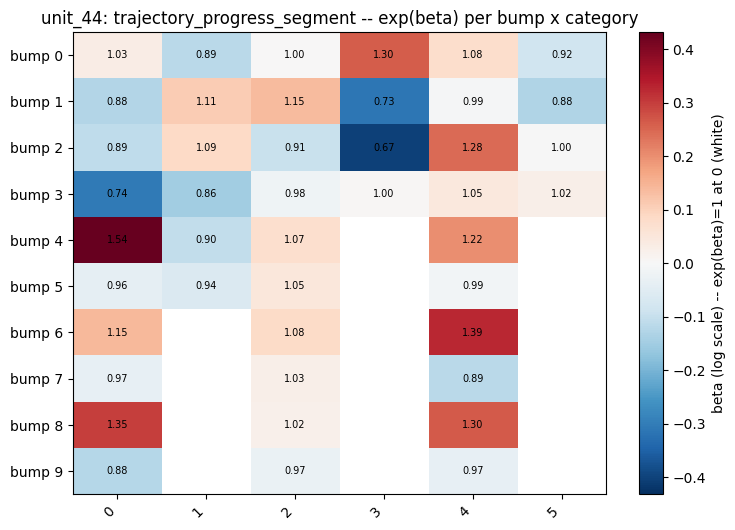

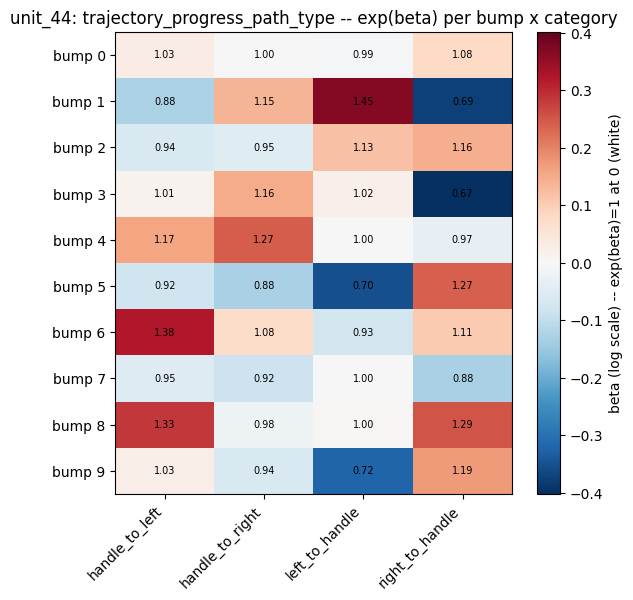

In [26]:
for base, cat in present:
    gp.plot_exp_beta_heatmap(w, feature_names, cat, unit_idx=unit_idx, unit_name=unit_name)
    plt.show()

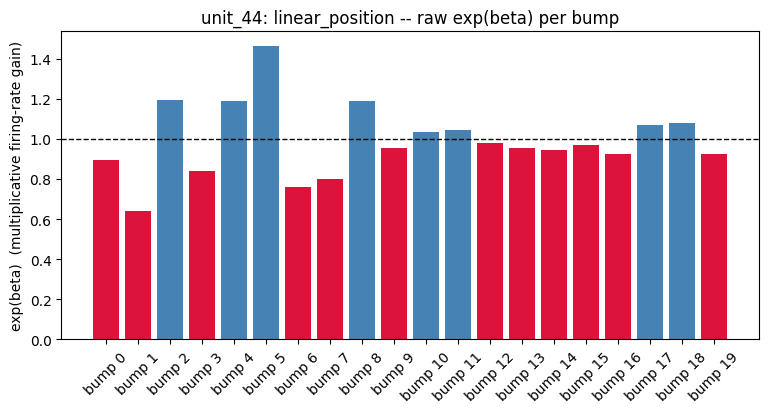

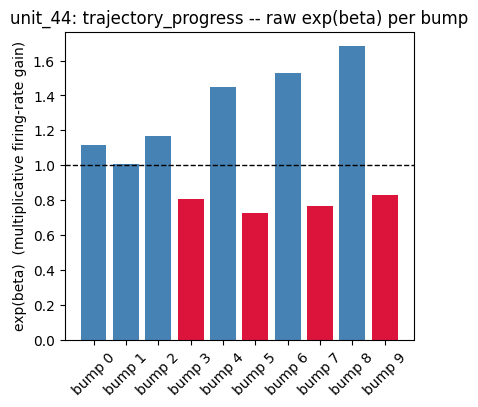

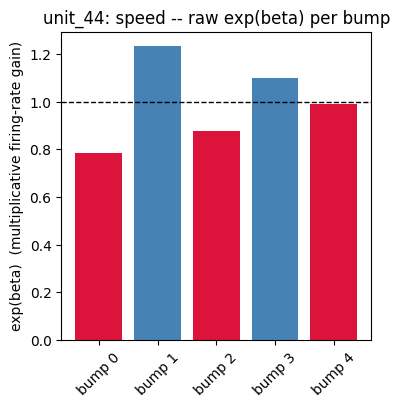

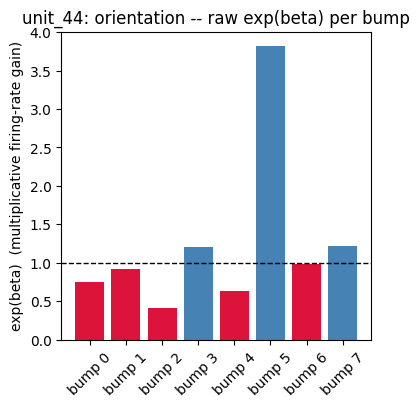

In [27]:
for var in usable_1d:
    gp.plot_exp_beta_bar(w, feature_names, var, unit_idx=unit_idx, unit_name=unit_name)
    plt.show()

### 2D position and predicted firing-rate maps
Predicted rate is `exp(X @ w + w0)` from the full design matrix, averaged over position, so it works even though `pos_2d` is skipped in the kernel-based plots.

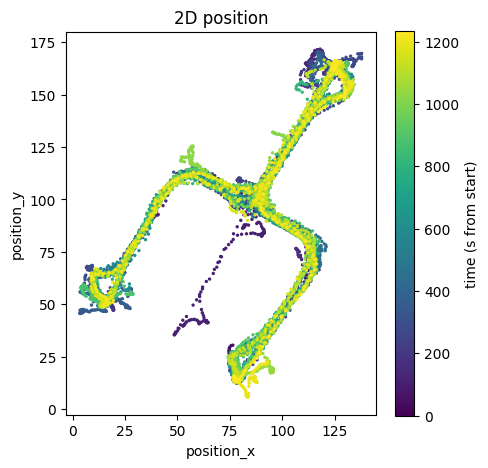

In [28]:
X = GLMBasis().fetch_design_matrix(fit_key)[0]
assert X.shape[0] == len(GLM_storage_df)  # same 50 ms bins, same order

gp.plot_position_2d(GLM_storage_df)
plt.show()

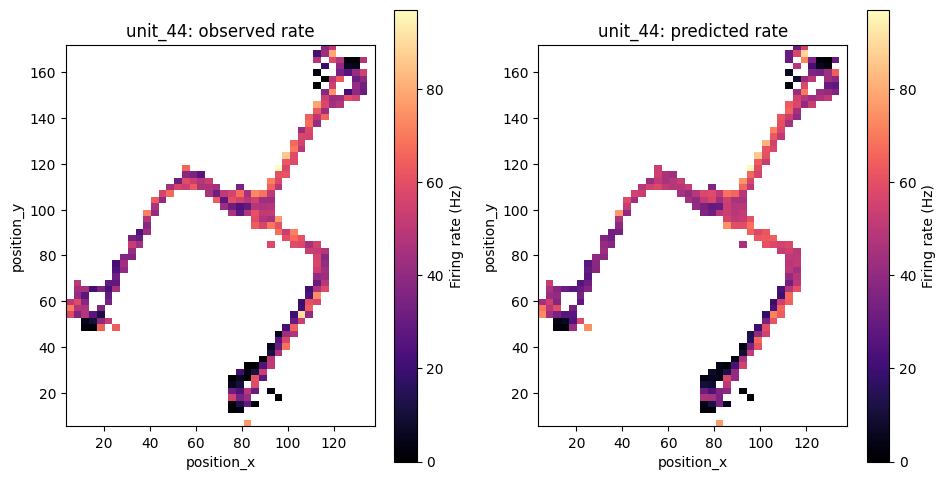

In [29]:
gp.plot_predicted_rate_map(GLM_storage_df, X, w, w0, unit_idx=unit_idx, unit_name=unit_name)
plt.show()

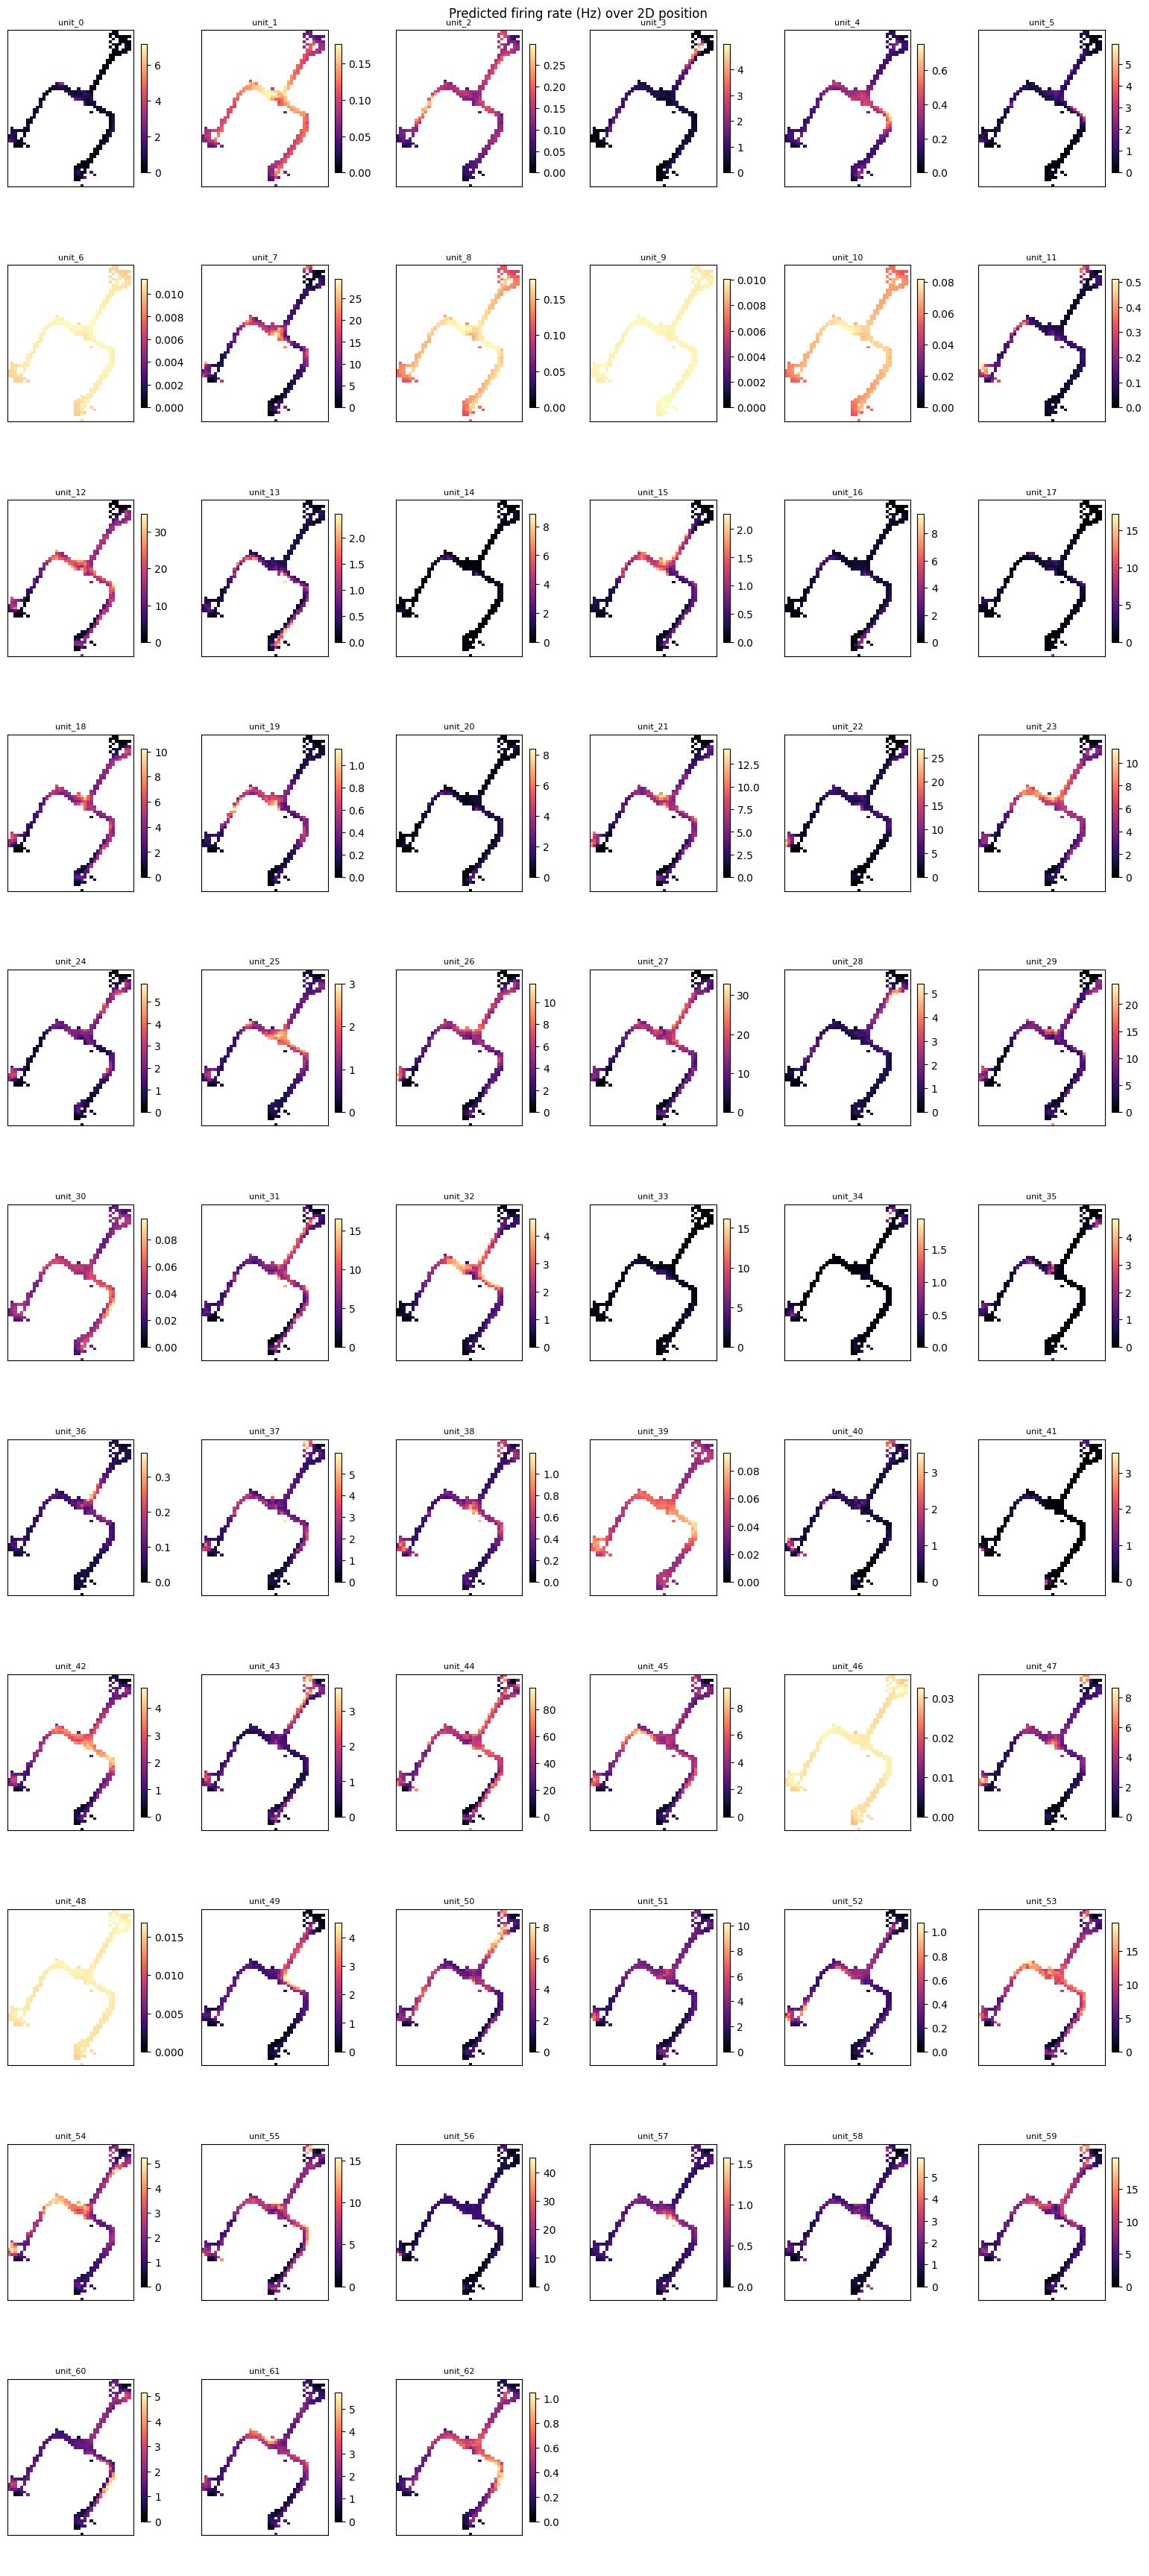

In [30]:
fig, axes = gp.plot_predicted_rate_maps_grid(
    GLM_storage_df, X, w, w0, unit_names=fit_results_df["unit_name"].tolist()
)
plt.show()